# SMARTRENT — Phase 2: Data Modeling
## คำถาม: คุณลักษณะห้องช่วยทำนายค่าเช่าที่ประกาศต่อเดือนได้ใกล้เคียงแค่ไหน?
เชื่อมกับ Phase 1: ช่วยเจ้าของห้องมีข้อมูลประกอบการประเมินค่าเช่า โมดูลค้นหา/กรองของผู้เช่ายังเป็นงานต่อ

**เครื่องมือ:** Python (Notebook เปิดใน Google Colab ได้); pandas อ่าน/ตรวจข้อมูล; scikit-learn สร้างโมเดล; matplotlib ทำกราฟ

Notebook นี้มีโค้ดและผลสำเร็จรูปจากการตรวจรันใน Python ภายในเครื่อง อ่านผลได้โดยไม่ต้องรันใหม่ การเปิดใน Colab เป็นทางเลือกสำหรับตรวจซ้ำหรือพัฒนาต่อ ไม่ใช่หลักฐานว่าเคยรันในบัญชี Colab ของทีม

ต้นฉบับไม่ถูกเขียนทับ ใช้ Dataset เดิมครบ 5 Sheets รายงานค่าเช่าประกาศ Snapshot มิถุนายน 2023 ตามผู้เผยแพร่ ข้อมูลทำเล/ตัวตนโครงการยังไม่รับรองทุกแถว


## ความเชื่อมโยงกับ Project Hints
Data Science: สำรวจข้อมูลใน Phase 1, โมเดลรอบแรกใน Phase 2 และโมเดลรอบสองพร้อมผลเปรียบเทียบใน Phase 3

เอกสารนี้จัดทำด้วยความช่วยเหลือของ AI สำหรับ Dataset ของทีม ผลรันที่แนบเป็นหลักฐานของการทดลอง ไม่ใช่หลักฐานว่าสมาชิกเขียนหรือรันเอง อาจารย์ระบุไม่ให้นำ Notebook ของผู้อื่นมาส่ง ทีมควรอธิบายวิธีทำและการใช้เครื่องมือตามจริง ไม่มีข้อกำหนดที่ตรวจพบว่าทุกคนต้องรัน Colab ซ้ำ


## 1. เตรียมเครื่องมือและแสดงเวอร์ชัน
ใช้ CPU ได้ เซลล์นี้ติดตั้งเวอร์ชันที่ตรวจไว้เมื่อรันใน Colab หากสภาพแวดล้อมต่างกันให้ตรวจเวอร์ชันก่อนเทียบผล

In [1]:
import sys, subprocess, importlib.util
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
        'numpy==2.5.4', 'pandas==3.0.1', 'scipy==1.18.1',
        'scikit-learn==1.9.1', 'matplotlib==3.11.2', 'joblib==1.6.0',
        'openpyxl>=3.1,<4', 'threadpoolctl>=3.5,<4'])
from pathlib import Path
from types import SimpleNamespace
import hashlib, json, re
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import joblib
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__, 'NumPy:', np.__version__, 'scikit-learn:', sklearn.__version__)
print('Execution environment:', 'Google Colab' if IN_COLAB else 'Local Python verification')

Python: 3.12.14
pandas: 3.0.1 NumPy: 2.5.4 scikit-learn: 1.9.1
Execution environment: Local Python verification


## 2. เปิด Excel ต้นฉบับ และสำรองทุก Sheet
ใน Colab ให้อัปโหลด 202306.xlsx เมื่อระบบถาม ไม่ต้องอัปโหลดไฟล์ cleaned ของชุดเก่า

In [2]:
SOURCE = Path('data/202306.xlsx') if Path('data/202306.xlsx').exists() else Path('202306.xlsx')
if not SOURCE.exists():
    from google.colab import files
    uploaded = files.upload()
    if '202306.xlsx' not in uploaded:
        raise ValueError('Please upload the original 202306.xlsx')
    SOURCE = Path('202306.xlsx')
OUT = Path('results_notebook'); OUT.mkdir(exist_ok=True)
FIG = OUT / 'figures'; FIG.mkdir(exist_ok=True)
sheets = pd.read_excel(SOURCE, sheet_name=None)
raw = sheets['Room'].copy()
inventory = pd.DataFrame([{'Sheet': k, 'Rows': len(v), 'Columns': len(v.columns)} for k, v in sheets.items()])
display(inventory)
print('SHA256:', hashlib.sha256(SOURCE.read_bytes()).hexdigest())
display(raw[['room_id','project_id','room_size','floor','unit_type','rental','rental_unit']].head())
inventory.to_csv(OUT/'raw_inventory.csv', index=False)

SHA256: 25b6253fdce323473b76479915885e3c76d323dbdd13fbf5cdfd10449570ff62


,Sheet,Rows,Columns
0,Room,10312,33
1,Project,241,29
2,Project Name,364,4
3,Project Unit Type,549,4
4,Property Nearby,11471,7


,room_id,project_id,room_size,floor,unit_type,rental,rental_unit
0,1,37,27 sq.m.,8th floor,1 Bedroom,10000,THB/month
1,2,46,24 sq.m.,24th floor,1 Bedroom,9000,THB/month
2,3,169,45 sq.m.,27th floor,1 Bedroom,10000,THB/month
3,4,46,36 sq.m.,4th floor,1 Bedroom,10000,THB/month
4,5,46,26 sq.m.,21st floor,1 Bedroom,11000,THB/month


## 3. Data Quality Assessment ก่อนเลือก Attribute
Count คือจำนวนค่าที่ไม่หาย; NUnique คือจำนวนค่าที่ต่างกัน ไม่ใช่คะแนนความสำคัญของตัวแปร การมีค่าหลากหลายไม่ได้แปลว่าต้องตัดเสมอ

In [3]:
quality = pd.DataFrame({'Attribute': raw.columns,
    'Dtype': [str(raw[c].dtype) for c in raw],
    'MissingVal': raw.isna().sum().values,
    'NUnique': raw.nunique(dropna=True).values,
    'Count': raw.count().values})
display(quality)
display(raw.rental_unit.value_counts(dropna=False).rename_axis('rental_unit').to_frame('Rows'))
print('Repeated listing URLs:', raw.duplicated('condo_link').sum())
quality.to_csv(OUT/'quality_raw.csv', index=False)

Repeated listing URLs: 3308


,Attribute,Dtype,MissingVal,NUnique,Count
0,room_id,int64,0,10312,10312
1,project_id,int64,0,237,10312
2,post_name,str,0,6568,10312
3,condo_link,str,0,7004,10312
4,last_update,datetime64[us],0,1603,10312
5,poster_name,str,773,345,9539
6,poster_status,str,773,2,9539
7,rental,int64,0,186,10312
8,rental_unit,str,0,3,10312
9,deposit,str,0,22,10312


,Rows
rental_unit,
THB/month,9507
Please contact,802
THB/day,3


## 4. ตรวจข้อขัดแย้งที่ทำให้ไม่ใช้ข้อมูลข้ามตาราง
ตรวจได้ว่าค่าขัดกัน แต่ยังไม่ทราบสาเหตุของผู้จัดทำ Dataset อย่าเดาว่ามาจาก Scraper ขั้นตอนไหน และอย่าพูดว่ารายการอื่นได้รับรองแล้ว

In [4]:
project = sheets['Project']; nearby = sheets['Property Nearby']
flagged = project.loc[project.project_id.isin([7,95,112,147,161]), ['project_id','project_name','address']]
display(flagged)
display(raw.loc[raw.project_id.eq(7), ['room_id','project_name','post_name']].head(2))
display(nearby.loc[nearby.project_id.eq(7) & nearby.property_type.eq('BTS Silom Line'),
    ['project_name','property_name','property_distance','property_distance_unit']])
flagged.to_csv(OUT/'flagged_project_groups.csv', index=False)

,project_id,project_name,address
6,7,Andaman Riviera,Thalang Phuket
94,95,Montrari Jomtien Beach View,Bang Lamung Chonburi
111,112,Pingpha,Bang Lamung Chonburi
146,147,Siam Oriental Twins,Bang Lamung Chonburi
160,161,South Beach,Bang Lamung Chonburi


,room_id,project_name,post_name
5414,5415,Andaman Riviera,Wonderful High Rise 2-BR Condo at Waterford Diamond Tower Sukhumvit near BTS Phrom Phong (ID 946291)
5415,5416,Andaman Riviera,Amazing High Rise 1-BR Condo at Waterford Diamond Tower Sukhumvit near BTS Phrom Phong (ID 946303)


,project_name,property_name,property_distance,property_distance_unit
294,Andaman Riviera,BTS Sala Daeng,0.4,m
326,Andaman Riviera,BTS Ratchadamri,0.4,m


## 5. เตรียมข้อมูลตามกฎที่ประกาศไว้
หนึ่งรายการต่อ URL; แยก 5 กลุ่มที่ติดข้อสงสัย; หน่วย THB/month; ค่าเช่าบวก; พื้นที่ศึกษา 15–400 ตร.ม.
ชั้นที่ตีความชัดเป็นจำนวน 1–100 ใช้ได้ ส่วนช่วง/ตัวอักษร/นอกช่วงเก็บ Missing โดยไม่เดา ไม่ Join คุณลักษณะ Project/Nearby

In [5]:
AMENITIES=['air_conditioner','digital_door_lock','furnished','hot_tub','in_room_wifi','kitchen_hood','kitchen_stove','phone','refrigerator','tv','washer','water_heater']
QUARANTINE={7:'Andaman Riviera: project/address vs listing-title conflict',95:'Montrari Jomtien: source address outside declared BTS Silom corridor',112:'Pingpha: source address outside declared BTS Silom corridor',147:'Siam Oriental Twins: source address outside declared BTS Silom corridor',161:'South Beach: source address outside declared BTS Silom corridor'}
def number(s):
    return pd.to_numeric(s.astype('string').str.replace(',','',regex=False).str.extract(r'(\d+(?:\.\d+)?)',expand=False),errors='coerce').astype(float)
def floor(v):
    m=re.fullmatch(r'\s*(\d+)(?:st|nd|rd|th)?(?:\s*floor)?\s*',str(v),re.I)
    return float(m[1]) if m and 1<=int(m[1])<=100 else np.nan
def prepare_room_data(source, output):
    a=SimpleNamespace(source=Path(source), output=Path(output));a.output.mkdir(parents=True,exist_ok=True)
    d=pd.read_excel(a.source,sheet_name='Room');log=[];bad=[]
    assert d.room_id.is_unique and d.condo_link.notna().all()
    core=['project_id','rental','rental_unit','room_size','floor','unit_type']
    assert not d.groupby('condo_link')[core].nunique(dropna=False).gt(1).any(axis=1).any()
    def keep(mask,label):
        nonlocal d
        mask=mask.fillna(False);b=d.loc[~mask,['room_id','project_id']].copy();b['reason']=label;bad.append(b)
        log.append({'step':label,'input_rows':len(d),'excluded_rows':int((~mask).sum()),'retained_rows':int(mask.sum())});d=d.loc[mask].copy()
    log.append({'step':'Original Room','input_rows':len(d),'excluded_rows':0,'retained_rows':len(d)})
    keep(~d.duplicated('condo_link'),'One record per listing URL')
    keep(~d.project_id.isin(QUARANTINE),'Quarantine five groups flagged by source audit (IDs 7,95,112,147,161)')
    keep(d.rental_unit.eq('THB/month'),'Explicit THB/month')
    d['rental']=pd.to_numeric(d.rental,errors='coerce');keep(np.isfinite(d.rental)&d.rental.gt(0),'Positive finite asking rent')
    d['size_sqm']=number(d.room_size);keep(d.size_sqm.between(15,400),'Declared size scope 15-400 sqm')
    d['floor_no']=d.floor.map(floor)
    d['bedrooms']=pd.to_numeric(d.unit_type.str.extract(r'(\d+)\s*Bedroom',expand=False),errors='coerce')
    d.loc[d.unit_type.eq('Studio'),'bedrooms']=0
    d['bedrooms']=d.bedrooms.fillna(number(d.no_bedroom))
    d['is_duplex']=d.unit_type.str.contains('Duplex',na=False).astype(int)
    for col in AMENITIES:
        assert d[col].isin([0,1]).all(),col
    d['n_reported_room_amenities']=d[AMENITIES].sum(axis=1)
    d['log_size']=np.log(d.size_sqm)
    columns=['room_id','project_id','condo_link','rental','size_sqm','log_size','floor_no','bedrooms','unit_type','is_duplex','n_reported_room_amenities']+AMENITIES
    d=d[columns].reset_index(drop=True)
    d.to_csv(a.output/'condo_clean.csv',index=False,encoding='utf-8-sig')
    pd.DataFrame(log).to_csv(a.output/'cleaning_log.csv',index=False,encoding='utf-8-sig')
    pd.concat(bad).to_csv(a.output/'excluded_rows.csv',index=False,encoding='utf-8-sig')
    pd.DataFrame({'column':d.columns,'missing_rows':d.isna().sum().values,'missing_pct':d.isna().mean().values*100}).to_csv(a.output/'missing_values.csv',index=False)
    manifest={'source_sha256':hashlib.sha256(a.source.read_bytes()).hexdigest(),'clean_rows':len(d),'recorded_groups':int(d.project_id.nunique()),'feature_source':'Room sheet only; no Project or Nearby join','quarantine':QUARANTINE,'floor_policy':'Unambiguous integer floor 1-100; ranges/letters/outside range treated as missing; no project-height cross-check','geography':'Source describes BTS Silom corridor; retained rows not individually geographically certified','snapshot':'June 2023 per publisher; listing last_update is a different timestamp','amenities':'1=reported, 0=unreported; no physical verification','target':'Advertised monthly asking rent, THB; no signed-contract target','identity':'Distinct URL is not proof of distinct physical unit; project_id used only as recorded grouping key'}
    (a.output/'data_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    print(pd.DataFrame(log).to_string(index=False));print('Room-only rows',len(d))

prepare_room_data(SOURCE, OUT)
df = pd.read_csv(OUT/'condo_clean.csv')
display(pd.read_csv(OUT/'cleaning_log.csv'))
display(pd.read_csv(OUT/'missing_values.csv').query('missing_rows > 0'))

                                                                 step  input_rows  excluded_rows  retained_rows
                                                        Original Room       10312              0          10312
                                           One record per listing URL       10312           3308           7004
Quarantine five groups flagged by source audit (IDs 7,95,112,147,161)        7004             21           6983
                                                   Explicit THB/month        6983            549           6434
                                          Positive finite asking rent        6434              0           6434
                                       Declared size scope 15-400 sqm        6434              9           6425
Room-only rows 6425


,step,input_rows,excluded_rows,retained_rows
0,Original Room,10312,0,10312
1,One record per listing URL,10312,3308,7004
2,"Quarantine five groups flagged by source audit (IDs 7,95,112,147,161)",7004,21,6983
3,Explicit THB/month,6983,549,6434
4,Positive finite asking rent,6434,0,6434
5,Declared size scope 15-400 sqm,6434,9,6425


,column,missing_rows,missing_pct
6,floor_no,817,12.715953


## 6. Attributes Selection พร้อมเหตุผล
เลือกเบื้องต้นตามชนิดข้อมูล/ความหมาย/ความพร้อม ไม่ใช่ผลพิสูจน์ว่า 18 ตัวนี้ดีที่สุด
ราคาเป็น Target จึงไม่ใช้เป็น Input; IDs/URL เป็นข้อมูลระบุรายการ; ชื่อโครงการและ Nearby ยังมีปัญหาการจับคู่; ชื่อผู้ลงประกาศ/ข้อความอิสระอยู่นอกขอบเขตรอบนี้

In [6]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 2026
ROOM = ['log_size','floor_no','bedrooms','is_duplex','n_reported_room_amenities',
        'air_conditioner','digital_door_lock','furnished','hot_tub','in_room_wifi',
        'kitchen_hood','kitchen_stove','phone','refrigerator','tv','washer','water_heater']
CAT = ['unit_type']
FEATURES = ROOM + CAT


def preprocessor(num, cat):
    return ColumnTransformer([
        ('numeric', Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),
                              ('scale',StandardScaler())]), num),
        ('categorical', Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
            ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)], sparse_threshold=0)


def model_pipeline(model, num, cat, log_target=True):
    reg = TransformedTargetRegressor(regressor=model,func=np.log1p,inverse_func=np.expm1) if log_target else model
    return Pipeline([('preprocess',preprocessor(num,cat)),('regressor',reg)])


def metrics(actual, predicted, projects):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    if not np.isfinite(predicted).all():
        raise ValueError('Non-finite model prediction')
    e = np.abs(actual-predicted)
    group_mae = pd.DataFrame({'project':np.asarray(projects),'ae':e}).groupby('project').ae.mean()
    return {'MAE_THB':float(e.mean()),'RMSE_THB':float(mean_squared_error(actual,predicted)**0.5),
            'R2':float(r2_score(actual,predicted)), 'MAPE_pct':float((e/actual).mean()*100),
            'within20_pct':float((e/actual<=0.2).mean()*100),
            'project_macro_MAE_THB':float(group_mae.mean())}



print('Input count before encoding:', len(FEATURES))
display(pd.DataFrame({'Feature': FEATURES, 'Role': ['Numeric' if c in ROOM else 'Categorical' for c in FEATURES]}))
assert not {'rental','room_id','project_id','district','project_age','rent_per_sqm'} & set(FEATURES)

Input count before encoding: 18


,Feature,Role
0,log_size,Numeric
1,floor_no,Numeric
2,bedrooms,Numeric
3,is_duplex,Numeric
4,n_reported_room_amenities,Numeric
5,air_conditioner,Numeric
6,digital_door_lock,Numeric
7,furnished,Numeric
8,hot_tub,Numeric
9,in_room_wifi,Numeric


## 7. Data Splitting
60/20/20 ของกลุ่ม project_id ที่บันทึกไว้ ไม่ใช่สัดส่วนแถว ไม่รับรองว่า ID เหล่านี้ถูกจับคู่กับโครงการจริงครบทั้งหมด จึงเรียกการประเมินย้อนหลังตาม recorded IDs

In [7]:
args=SimpleNamespace(output=OUT)
forbidden={'rental','rent_per_sqm','log_rent','rent_per_sqm_review','room_id','project_id','project_name'}
assert not forbidden.intersection(FEATURES)
assert not any(c.startswith('nearest_') or c.endswith('_3km') for c in FEATURES)
dev_i,test_i=next(GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=SEED).split(df,groups=df.project_id))
dev=df.iloc[dev_i].copy();test=df.iloc[test_i].copy()
train_i,val_i=next(GroupShuffleSplit(n_splits=1,test_size=0.25,random_state=SEED+1).split(dev,groups=dev.project_id))
train=dev.iloc[train_i].copy();val=dev.iloc[val_i].copy()
sets=[set(d.project_id) for d in [train,val,test]]
assert not (sets[0]&sets[1] or sets[0]&sets[2] or sets[1]&sets[2])
split_rows=[]
for name,d in [('train',train),('validation',val),('test',test)]:
    s=d[['room_id','project_id']].copy();s['split']=name;split_rows.append(s)
    print(f'{name}: {len(d):,} listings / {d.project_id.nunique()} recorded groups',flush=True)
pd.concat(split_rows).to_csv(args.output/'split_assignments.csv',index=False)


split_summary=pd.DataFrame([{'Split': n, 'Listings': len(d), 'RecordedGroups': d.project_id.nunique()} for n,d in [('Train',train),('Validation',val),('Test',test)]])
display(split_summary)

train: 4,217 listings / 138 recorded groups
validation: 1,408 listings / 46 recorded groups
test: 800 listings / 46 recorded groups


,Split,Listings,RecordedGroups
0,Train,4217,138
1,Validation,1408,46
2,Test,800,46


## 8. EDA / Correlation Heatmap
คำนวณบน Train เท่านั้น Pearson correlation ใช้สำรวจความสัมพันธ์ ไม่พิสูจน์เหตุและผล ไม่ใช้ ID เป็นตัวเลขวิเคราะห์

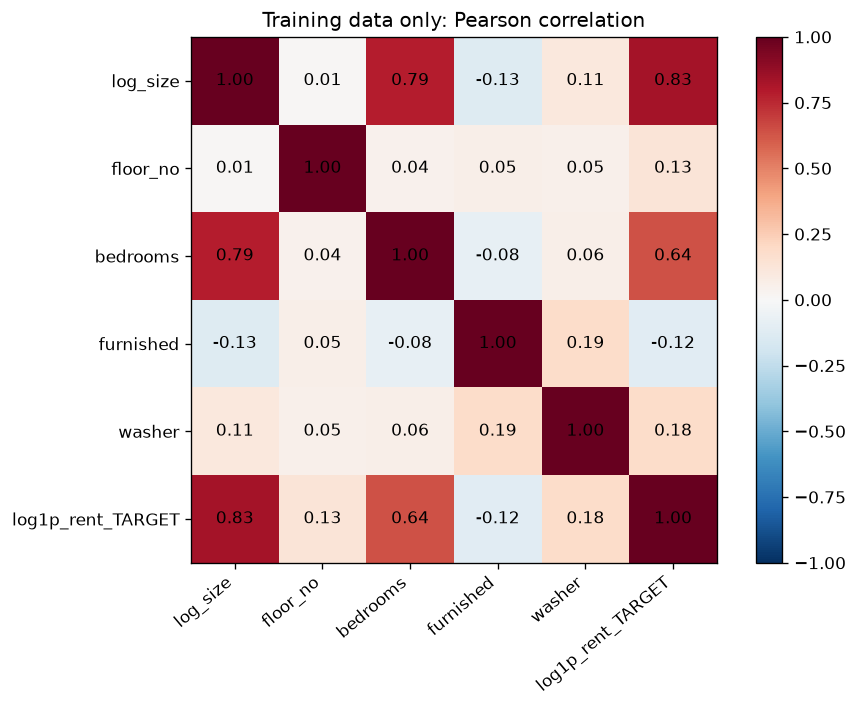

In [8]:
heat = train[['log_size','floor_no','bedrooms','furnished','washer']].copy()
heat['log1p_rent_TARGET'] = np.log1p(train.rental)
corr = heat.corr(method='pearson')
fig, ax = plt.subplots(figsize=(8,6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha='right')
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=10)
fig.colorbar(im,ax=ax); ax.set_title('Training data only: Pearson correlation')
fig.tight_layout(); fig.savefig(FIG/'correlation_train.png',dpi=200); plt.show()
corr.to_csv(OUT/'correlation_train.csv')

## 9. Model Experiments / Hyperparameter Tuning
Ridge alpha=10 กำหนดไว้; RF ใช้ค่าตั้งต้นที่ประกาศ; HGB ทดลอง 8 ชุดด้วย 3-fold GroupKFold ภายใน Train แล้วเปรียบเทียบทุกโมเดลด้วย Validation MAE ในหน่วยบาท

In [9]:
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=2):
    candidates={
        'Median baseline':model_pipeline(DummyRegressor(strategy='median'),ROOM,['unit_type'],False),
        'Ridge log rent':model_pipeline(Ridge(alpha=10),ROOM,CAT),
        'Random Forest rooms':model_pipeline(RandomForestRegressor(n_estimators=160,min_samples_leaf=5,
            max_features=0.8,n_jobs=2,random_state=SEED),ROOM,['unit_type']),
    }
    # early_stopping=False prevents an internal random validation split across projects.
    hgb=model_pipeline(HistGradientBoostingRegressor(max_iter=220,early_stopping=False,random_state=SEED),ROOM,CAT)
    grid={'regressor__regressor__learning_rate':[0.05,0.1],
          'regressor__regressor__max_leaf_nodes':[15,31],
          'regressor__regressor__l2_regularization':[1.0,10.0]}
    search=GridSearchCV(hgb,grid,scoring='neg_mean_absolute_error',cv=GroupKFold(n_splits=3),
                        n_jobs=1,error_score='raise')
    search.fit(train[FEATURES],train.rental,groups=train.project_id)
    candidates['Gradient Boosting tuned']=search.best_estimator_
    pd.DataFrame(search.cv_results_).to_csv(args.output/'training_cv_search.csv',index=False)
    rows=[];fitted={}
    for name,est in candidates.items():
        fit=clone(est).fit(train[FEATURES],train.rental)
        prediction=fit.predict(val[FEATURES])
        rows.append({'model':name,**metrics(val.rental,prediction,val.project_id)})
        fitted[name]=fit
        print(name,round(rows[-1]['MAE_THB'],2),flush=True)
    comparison=pd.DataFrame(rows).sort_values('MAE_THB').reset_index(drop=True)
    comparison.to_csv(args.output/'validation_results.csv',index=False)

    selected=str(comparison.iloc[0]['model'])
    display(comparison)
    print('Selected by Validation MAE:', selected)

Median baseline 14660.45
Ridge log rent 9018.11
Random Forest rooms 10540.65
Gradient Boosting tuned 9784.73
Selected by Validation MAE: Ridge log rent


,model,MAE_THB,RMSE_THB,R2,MAPE_pct,within20_pct,project_macro_MAE_THB
0,Ridge log rent,9018.112274,14307.842020,0.595859,31.180626,38.210227,15745.943813
1,Gradient Boosting tuned,9784.729045,16079.586364,0.489572,32.709005,40.909091,16695.246035
2,Random Forest rooms,10540.648143,17205.634014,0.415579,34.713987,37.784091,17608.370251
3,Median baseline,14660.448153,23097.677780,-0.053225,57.646453,27.059659,24029.666285


## 10. Model Evaluation
เลือกโมเดลแล้วจึง Refit Train+Validation และรายงาน Test ไม่ปรับให้คะแนน Test สวยขึ้น นี่เป็นการทดลองย้อนหลังหลังแก้ขอบเขตจากการตรวจข้อมูล ไม่ใช่ External/Future test ใหม่

In [10]:
# Choice is fixed before test predictions; refit on all development projects.
final=clone(candidates[selected]).fit(dev[FEATURES],dev.rental)
baseline=clone(candidates['Median baseline']).fit(dev[FEATURES],dev.rental)
pred=final.predict(test[FEATURES]);base_pred=baseline.predict(test[FEATURES])
final_rows=[{'model':selected,**metrics(test.rental,pred,test.project_id)},
            {'model':'Median baseline',**metrics(test.rental,base_pred,test.project_id)}]
pd.DataFrame(final_rows).to_csv(args.output/'test_results.csv',index=False)
prediction_table=test[['room_id','project_id','unit_type','size_sqm','floor_no','rental']].copy()
prediction_table=prediction_table.rename(columns={'rental':'actual_asking_rent_THB'})
prediction_table['predicted_asking_rent_THB']=pred
prediction_table['absolute_error_THB']=np.abs(test.rental.to_numpy()-pred)
prediction_table['absolute_error_pct']=prediction_table.absolute_error_THB/prediction_table.actual_asking_rent_THB*100
prediction_table.to_csv(args.output/'test_predictions.csv',index=False,encoding='utf-8-sig')
# Fixed random examples, not cherry-picked for small errors.
prediction_table.sample(min(8,len(prediction_table)),random_state=SEED).to_csv(args.output/'demo_examples.csv',index=False,encoding='utf-8-sig')
per_project=prediction_table.groupby(['project_id']).agg(listings=('room_id','size'),
    MAE_THB=('absolute_error_THB','mean')).reset_index().sort_values('MAE_THB',ascending=False)
per_project.to_csv(args.output/'test_error_by_project.csv',index=False,encoding='utf-8-sig')
joblib.dump(final,args.output/'rent_model.joblib')
sample=test[FEATURES].head(1)
sample.to_csv(args.output/'example_model_input.csv',index=False)
loaded=joblib.load(args.output/'rent_model.joblib')
np.testing.assert_allclose(loaded.predict(sample),final.predict(sample))

print('Test results (THB/month):')
display(pd.DataFrame(final_rows))
print('Within 20% count:', int((np.abs(test.rental.to_numpy()-pred)/test.rental.to_numpy() <= .2).sum()), '/', len(test))

Test results (THB/month):
Within 20% count: 251 / 800


,model,MAE_THB,RMSE_THB,R2,MAPE_pct,within20_pct,project_macro_MAE_THB
0,Ridge log rent,13866.355268,29879.921466,0.708932,34.100326,31.375,20341.924585
1,Median baseline,27086.500000,58044.822368,-0.098403,61.740473,17.500,43120.596950


## 11. ตัวอย่าง Prediction และกราฟผลทดสอบ
ราคาจริงเป็นเฉลยที่เก็บไว้ ไม่ส่งเข้าโมเดล ตัวอย่างเลือกไว้ล่วงหน้าเพื่ออธิบาย ไม่ใช่ตัวอย่างสุ่ม และไม่ใช่ตัวแทนความแม่นยำทั้งหมด

,room_id,size_sqm,actual_asking_rent_THB,predicted_asking_rent_THB,absolute_error_THB
0,1084,48.0,15000,20458.521757,5458.521757
1,3228,197.0,70000,119760.694545,49760.694545
2,10208,55.0,30000,26466.735418,3533.264582


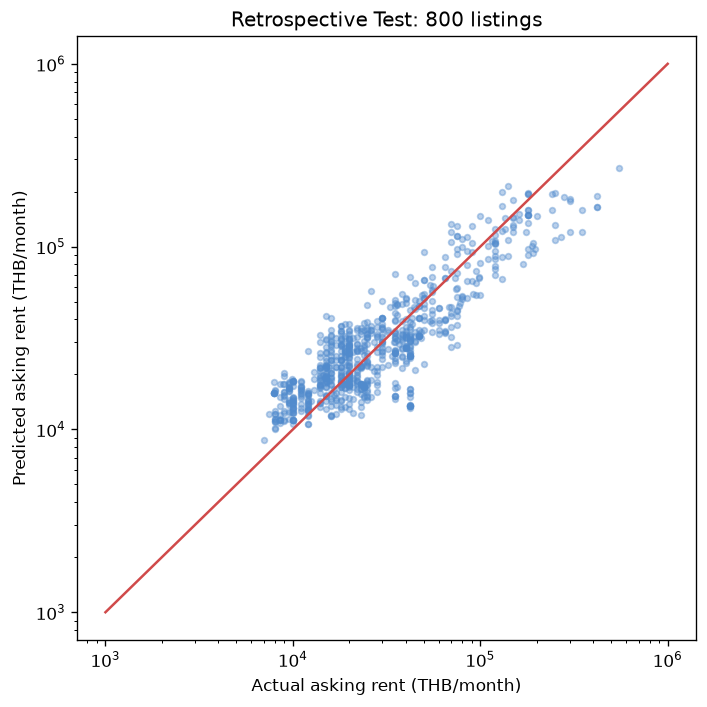

In [11]:
examples = prediction_table.set_index('room_id').loc[[1084,3228,10208]].reset_index()
display(examples[['room_id','size_sqm','actual_asking_rent_THB','predicted_asking_rent_THB','absolute_error_THB']])
examples.to_csv(OUT/'presentation_examples.csv',index=False)
fig, ax = plt.subplots(figsize=(6,6))
ax.scatter(test.rental,pred,s=12,alpha=.4,color='#518BCD')
ax.plot([1000,1000000],[1000,1000000],color='#D04A4A')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set(xlabel='Actual asking rent (THB/month)',ylabel='Predicted asking rent (THB/month)',title='Retrospective Test: 800 listings')
fig.tight_layout(); fig.savefig(FIG/'actual_vs_predicted.png',dpi=200); plt.show()

## 12. โหลดโมเดลกลับมาทำนายจาก Features
นี่คือส่วนที่ต่อกับหน้าจอใน Phase 3 ได้ ตอนนี้รับ Feature CSV ที่เตรียมตาม Schema ไม่ใช่ข้อความอะไรก็ได้

In [12]:
saved = joblib.load(OUT/'rent_model.joblib')
example_input = pd.read_csv(OUT/'example_model_input.csv')
assert 'rental' not in example_input
display(example_input)
display(pd.DataFrame({'predicted_asking_rent_THB': saved.predict(example_input[FEATURES])}))
np.testing.assert_allclose(saved.predict(test[FEATURES]), prediction_table.predicted_asking_rent_THB)
receipt = {'execution_environment': 'Google Colab' if IN_COLAB else 'Local Python verification',
    'source_sha256': hashlib.sha256(SOURCE.read_bytes()).hexdigest(),
    'python': sys.version, 'pandas': pd.__version__, 'sklearn': sklearn.__version__,
    'feature_count': len(FEATURES), 'features': FEATURES,
    'selected_model': selected, 'test_results': final_rows,
    'scope': 'Revised retrospective holdout by recorded project_id; geography/entity identities not fully certified'}
(OUT/'execution_receipt.json').write_text(json.dumps(receipt,ensure_ascii=False,indent=2),encoding='utf-8')
print('Saved results:', OUT.resolve())

Saved results: C:\Users\computer\Documents\Codex\2026-10-15\data-sciene-pdf-prediction-dataset-data\outputs\SMARTRENT_FINAL_SUBMISSION_20261019\results_notebook


,log_size,floor_no,bedrooms,is_duplex,n_reported_room_amenities,air_conditioner,digital_door_lock,furnished,hot_tub,in_room_wifi,kitchen_hood,kitchen_stove,phone,refrigerator,tv,washer,water_heater,unit_type
0,3.295837,8.0,1.0,0,3,1,0,1,0,0,0,0,0,0,0,0,1,1 Bedroom


,predicted_asking_rent_THB
0,11214.759431


## 13. เก็บผลสำเร็จรูป
ไฟล์ ZIP ประกอบด้วยตาราง กราฟ โมเดล และหลักฐานการรัน ผู้รับสามารถดู Notebook_Results.html โดยไม่ต้องติดตั้งหรือรันอะไรเพิ่ม


In [13]:
import shutil
archive = shutil.make_archive('SMARTRENT_notebook_results','zip',OUT)
print('Result archive:', archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Result archive: C:\Users\computer\Documents\Codex\2026-10-15\data-sciene-pdf-prediction-dataset-data\outputs\SMARTRENT_FINAL_SUBMISSION_20261019\SMARTRENT_notebook_results.zip


## การตีความและงานต่อ
- MAE 13,866.36 บาท หมายถึงความผิดพลาดสัมบูรณ์เฉลี่ย ไม่ใช่เพดานทุกห้อง
- R² ไม่ใช่ Accuracy; Within20 เป็นสัดส่วน Test ไม่ใช่ Confidence interval
- Room-only ยังผิดมาก การเพิ่มข้อมูลโครงการต้องตรวจการจับคู่ก่อน ไม่ใส่ระยะ BTS ที่ยังไม่ยืนยัน
- โมเดลประมาณค่าเช่าเชื่อมกับฝั่งเจ้าของห้องใน Phase 1 ส่วนผู้เช่าต้องมีการค้นหา/กรองเพิ่ม
- แหล่งข้อมูล: https://www.kaggle.com/datasets/krityodp/condominium-data-in-bangkok/data
- วิธีใช้ Colab: https://research.google.com/colaboratory/faq.html
- วิธีป้องกัน leakage: https://scikit-learn.org/stable/common_pitfalls.html
